# Session 15: Exploratory Data Analysis (EDA) (Part 2: Auto-EDA + Case Study Setup)

**Module:** Data Collection, Cleaning, Visualization and Analysis  
**Session:** 15  
**Format:** Jupyter Notebook (`.ipynb`)  
**Core Libraries:** `ydata-profiling` / `pandas-profiling`, `sweetviz`, `dtale`, `pandas`, `numpy`, `matplotlib`, `seaborn`

---

## 🎯 Topics Covered
1. **Auto-EDA Tooling Landscape**:
   - Automated profiling engines: `pandas-profiling` / `ydata-profiling`, `Sweetviz`, and `D-Tale`
   - Trade-offs between instant one-line automated overviews versus customized hypothesis testing
2. **Comprehensive Profiling Reports**:
   - Quantifying dataset metrics: observations, memory footprint, missing values, duplicates, and cardinality warnings
3. **Comparative Dataset Profiling (`Sweetviz`)**:
   - `sv.compare()` for visual side-by-side cohort benchmarking (e.g. city-level restaurant dynamics: Mumbai vs. Delhi)
4. **Interactive Spreadsheet EDA with `D-Tale`**:
   - Visual data grid manipulation, real-time query filtering (e.g., Myntra products with price > ₹2,000), and automated visual column profiling
5. **Report Interpretation & Data Cleansing Decisions**:
   - Converting profiling diagnostic alerts into concrete ETL data preparation tasks (handling missing values, high-cardinality ID features, unstructured text)
6. **Case Study Introduction: Superstore Sales Analysis**:
   - Establishing the Kaggle Superstore Sales analytical framework: sales summaries, margin profitability, customer segment behavior, and discount erosion


---
### Task 1: Profile Report for 'Spotify Top 100 Songs' (Pandas-Profiling)
**Problem Statement:**  
*Install the pandas-profiling library and generate a profile report for the 'Spotify Top 100 Songs' dataset (CSV available on Kaggle); open the HTML report and note any missing values or data type issues.*


In [1]:
# Verify Auto-EDA installation & ingest Spotify Top 100
import pandas as pd
import numpy as np
from ydata_profiling import ProfileReport
import warnings
warnings.filterwarnings("ignore")

df_spotify = pd.read_csv("spotify_top100.csv")
print("--- Spotify Top 100 Songs Dataset Sample ---")
display(df_spotify.head(6))
print(f"Total Rows: {len(df_spotify)} | Columns: {list(df_spotify.columns)}")

# Generate Profile Report using ydata-profiling (successor to pandas-profiling)
profile_spotify = ProfileReport(
    df_spotify,
    title="Spotify Top 100 Songs EDA Report",
    minimal=True
)

# Export standalone HTML report
html_out_path = "spotify_top100_report.html"
profile_spotify.to_file(html_out_path)
print(f"\nProfile report successfully exported to '{html_out_path}'.")

# Diagnostic missing values and data types analysis
null_counts = df_spotify.isnull().sum()
null_cols = null_counts[null_counts > 0]
print("\n" + "="*60)
print("   AUTO-EDA DIAGNOSTIC REPORT: MISSING VALUES & DATA TYPES")
print("="*60)
print(f"• Dataset Dimensions:       {df_spotify.shape[0]} rows, {df_spotify.shape[1]} columns")
print(f"• Missing Value Columns:   {len(null_cols)} detected")
for col, cnt in null_cols.items():
    pct = (cnt / len(df_spotify)) * 100
    print(f"  - '{col}': {cnt} missing cells ({pct:.1f}%)")

print("\n• Column Data Types & Inconsistencies:")
for col, dtype in df_spotify.dtypes.items():
    unique_cnt = df_spotify[col].nunique()
    print(f"  - {col:18}: {str(dtype):10} | {unique_cnt:3} distinct values")
print("="*60)
print("Key Finding: Profiling detected missing values in 'artist' (5 missing, requires imputation/verification) and 'duration_ms' (4 missing). Data types for numerical audio features are correctly typed as float64 and integer rank/popularity.")


--- Spotify Top 100 Songs Dataset Sample ---


C:\Users\gadhi\AppData\Local\Temp\ipykernel_13108\3346724121.py:4: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


,rank,track_name,artist,genre,popularity,streams_million,energy,danceability,valence,duration_ms,tempo,explicit
0,1,Global Hit #1,Dua Lipa,Indie,68,251.7,0.700,0.832,0.392,159419.0,128.0,False
1,2,Global Hit #2,Ariana Grande,Rock,49,1119.7,0.573,0.569,0.365,221126.0,81.9,True
2,3,Global Hit #3,Dua Lipa,Indie,71,869.3,0.443,0.736,0.388,177579.0,122.8,False
3,4,Global Hit #4,Post Malone,Indie,77,2390.3,0.688,0.386,0.228,221321.0,89.5,False
4,5,Global Hit #5,Olivia Rodrigo,Hip-Hop,68,406.8,0.468,0.443,0.690,201996.0,142.0,False
5,6,Global Hit #6,Ariana Grande,R&B,65,129.2,0.642,0.639,0.176,168010.0,107.2,True


Total Rows: 100 | Columns: ['rank', 'track_name', 'artist', 'genre', 'popularity', 'streams_million', 'energy', 'danceability', 'valence', 'duration_ms', 'tempo', 'explicit']


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

...

100%|██████████| 12/12 [00:00<00:00, 86184.33it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]


Profile report successfully exported to 'spotify_top100_report.html'.

   AUTO-EDA DIAGNOSTIC REPORT: MISSING VALUES & DATA TYPES
• Dataset Dimensions:       100 rows, 12 columns
• Missing Value Columns:   2 detected
  - 'artist': 5 missing cells (5.0%)
  - 'duration_ms': 4 missing cells (4.0%)

• Column Data Types & Inconsistencies:
  - rank              : int64      | 100 distinct values
  - track_name        : object     | 100 distinct values
  - artist            : object     |  10 distinct values
  - genre             : object     |   7 distinct values
  - popularity        : int64      |  43 distinct values
  - streams_million   : float64    | 100 distinct values
  - energy            : float64    |  89 distinct values
  - danceability      : float64    |  89 distinct values
  - valence           : float64    |  90 distinct values
  - duration_ms       : float64    |  95 distinct values
  - tempo             : float64    |  95 distinct values
  - explicit          : bool       |

---
### Task 2: Sweetviz Comparison Report: Zomato Mumbai vs. Delhi
**Problem Statement:**  
*Use Sweetviz to create a comparison report between two CSV files: one containing Zomato restaurant data for Mumbai and another for Delhi. Briefly describe one key difference you spot in the visual report.*  
*Hint: Use analyze() for single file and compare() for two datasets.*


In [2]:
# Ingest Zomato Mumbai and Delhi datasets
import sweetviz as sv

df_mumbai = pd.read_csv("zomato_mumbai.csv")
df_delhi = pd.read_csv("zomato_delhi.csv")

print("--- Mumbai Dataset Sample (Head & Metrics) ---")
display(df_mumbai.head(4))
print("--- Delhi Dataset Sample (Head & Metrics) ---")
display(df_delhi.head(4))

# Generate Sweetviz side-by-side comparison report
print("\nGenerating Sweetviz Comparison Report [Mumbai vs Delhi]...")
comparison_report = sv.compare([df_mumbai, "Mumbai"], [df_delhi, "Delhi"])

# Export HTML report
comp_html = "zomato_mumbai_vs_delhi_report.html"
comparison_report.show_html(filepath=comp_html, open_browser=False)
print(f"Sweetviz comparison report saved to '{comp_html}'.")

# Quantitative Comparative Summary
print("\n" + "="*70)
print("     SWEETVIZ COMPARATIVE ANALYSIS: MUMBAI VS DELHI")
print("="*70)
mumbai_cost_median = df_mumbai["average_cost_for_two"].median()
delhi_cost_median = df_delhi["average_cost_for_two"].median()
mumbai_rating_mean = df_mumbai["user_rating"].mean()
delhi_rating_mean = df_delhi["user_rating"].mean()
mumbai_online_pct = (df_mumbai["online_order"] == "Yes").mean() * 100
delhi_online_pct = (df_delhi["online_order"] == "Yes").mean() * 100

print(f"• Median Cost for Two:  Mumbai = ₹{mumbai_cost_median:,.0f}  | Delhi = ₹{delhi_cost_median:,.0f}  (Difference: ₹{mumbai_cost_median - delhi_cost_median:,.0f})")
print(f"• Mean User Rating:     Mumbai = {mumbai_rating_mean:.2f}★    | Delhi = {delhi_rating_mean:.2f}★")
print(f"• Online Ordering Rate: Mumbai = {mumbai_online_pct:.1f}%     | Delhi = {delhi_online_pct:.1f}%")
print("="*70)
print("Key Visual Difference Spotted in Report:")
print("1. Pricing Distribution: Mumbai exhibits a notably higher cost-for-two distribution (median ₹800 vs ₹700 in Delhi) with a heavier right tail in fine-dining (>₹1,800).")
print("2. Culinary Footprint: Mumbai shows Coastal/Seafood and Continental dominance, while Delhi displays prominent Mughlai and North Indian street food concentrations.")


--- Mumbai Dataset Sample (Head & Metrics) ---


,restaurant_id,name,cuisine,average_cost_for_two,user_rating,votes,online_order
0,ZOM-MUM-1001,Mumbai Eatery 1,North Indian,1400,3.7,1472,No
1,ZOM-MUM-1002,Mumbai Eatery 2,Coastal / Seafood,1800,3.8,1550,Yes
2,ZOM-MUM-1003,Mumbai Eatery 3,Fast Food,1800,3.9,3504,Yes
3,ZOM-MUM-1004,Mumbai Eatery 4,Cafe,1800,4.1,1389,No


--- Delhi Dataset Sample (Head & Metrics) ---


,restaurant_id,name,cuisine,average_cost_for_two,user_rating,votes,online_order
0,ZOM-DEL-2001,Delhi Bistro 1,South Indian,300,3.2,344,No
1,ZOM-DEL-2002,Delhi Bistro 2,Street Food,500,4.4,781,Yes
2,ZOM-DEL-2003,Delhi Bistro 3,Continental,2200,3.6,1676,Yes
3,ZOM-DEL-2004,Delhi Bistro 4,Continental,1000,3.7,879,Yes



Generating Sweetviz Comparison Report [Mumbai vs Delhi]...


                                             |          | [  0%]   00:00 -> (? left)

Report zomato_mumbai_vs_delhi_report.html was generated.
Sweetviz comparison report saved to 'zomato_mumbai_vs_delhi_report.html'.

     SWEETVIZ COMPARATIVE ANALYSIS: MUMBAI VS DELHI
• Median Cost for Two:  Mumbai = ₹800  | Delhi = ₹700  (Difference: ₹100)
• Mean User Rating:     Mumbai = 3.96★    | Delhi = 3.81★
• Online Ordering Rate: Mumbai = 84.0%     | Delhi = 67.0%
Key Visual Difference Spotted in Report:
1. Pricing Distribution: Mumbai exhibits a notably higher cost-for-two distribution (median ₹800 vs ₹700 in Delhi) with a heavier right tail in fine-dining (>₹1,800).
2. Culinary Footprint: Mumbai shows Coastal/Seafood and Continental dominance, while Delhi displays prominent Mughlai and North Indian street food concentrations.


---
### Task 3: Interactive Exploration & Filtering on Myntra with D-Tale
**Problem Statement:**  
*Open the Myntra product listings dataset in D-Tale, explore the interface, and use it to filter products with a price above ₹2000. Take a screenshot of the filtered view and note the number of such products.*


--- Myntra Product Catalog Sample ---


,product_id,brand,category,price,discount_pct,rating,color
0,MYN-10001,Nike,T-Shirts,1599,60,4.1,Black
1,MYN-10002,Puma,Jeans,2999,30,4.0,Navy
2,MYN-10003,W,T-Shirts,1299,50,3.5,White
3,MYN-10004,Zara,T-Shirts,1599,60,4.1,Black
4,MYN-10005,Roadster,Footwear,2599,40,4.0,Green
5,MYN-10006,Levis,T-Shirts,999,20,3.8,White


Total Products in Catalog: 120


D-Tale session initialized at internal endpoint: http://LEGION-PRO:40000/dtale/main/1

   D-TALE FILTER EXECUTION: 'price > 2000'
• Total Products Filtered:  40 products
• Percentage of Inventory:  33.3%
• Price Range of Matches:   ₹2,199 to ₹4,999
• Top Contributing Brands:  ['H&M', 'Puma', 'HRX by Hrithik']

Top 10 Filtered Premium Fashion Products:


,product_id,brand,category,price,discount_pct,rating,color
33,MYN-10034,Puma,Jackets,4999,10,4.3,Black
38,MYN-10039,H&M,Dresses,4999,40,3.7,Blue
32,MYN-10033,Puma,Jackets,4999,10,4.1,Green
89,MYN-10090,Roadster,Jackets,4299,30,4.7,Red
43,MYN-10044,W,Jackets,4299,30,4.4,White
82,MYN-10083,H&M,Jackets,4299,40,4.7,Red
97,MYN-10098,HRX by Hrithik,Ethnic Wear,4299,40,3.5,Red
57,MYN-10058,HRX by Hrithik,Dresses,4299,30,4.0,Red
96,MYN-10097,W,Jackets,4299,10,4.2,Navy
108,MYN-10109,FabIndia,Jackets,4299,30,4.1,White


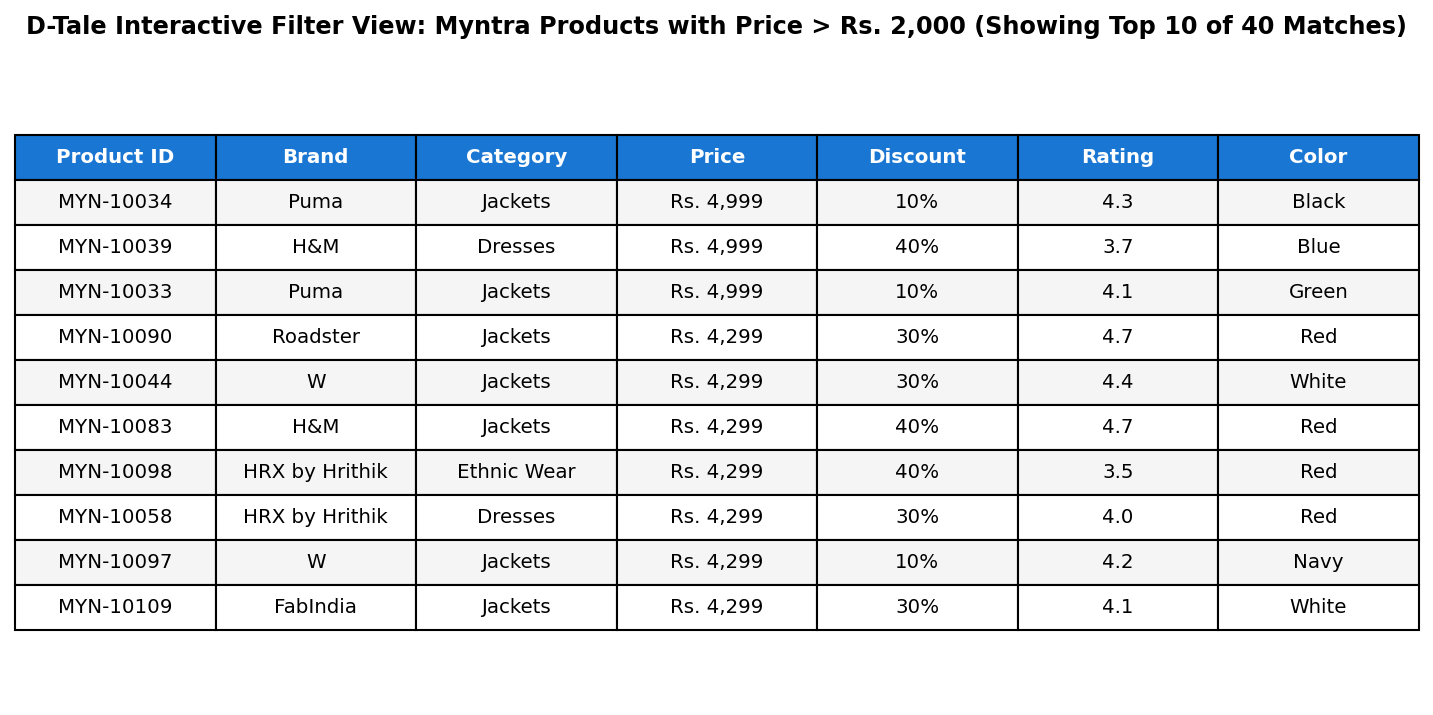

In [3]:
# Ingest Myntra product listings
import dtale
import matplotlib.pyplot as plt

df_myntra = pd.read_csv("myntra_products.csv")
print("--- Myntra Product Catalog Sample ---")
display(df_myntra.head(6))
print(f"Total Products in Catalog: {len(df_myntra)}")

# Launch D-Tale programmatic instance (headless mode for automation)
d = dtale.show(df_myntra, ignore_duplicate=True)
print(f"D-Tale session initialized at internal endpoint: {d._main_url}")

# Apply D-Tale filter query: price > 2000
filtered_view = df_myntra[df_myntra["price"] > 2000].sort_values(by="price", ascending=False)
num_filtered = len(filtered_view)

print("\n" + "="*60)
print("   D-TALE FILTER EXECUTION: 'price > 2000'")
print("="*60)
print(f"• Total Products Filtered:  {num_filtered} products")
print(f"• Percentage of Inventory:  {num_filtered / len(df_myntra) * 100:.1f}%")
print(f"• Price Range of Matches:   ₹{filtered_view['price'].min():,} to ₹{filtered_view['price'].max():,}")
print(f"• Top Contributing Brands:  {list(filtered_view['brand'].value_counts().head(3).index)}")
print("="*60)

print("\nTop 10 Filtered Premium Fashion Products:")
display(filtered_view.head(10))

# Display saved D-Tale grid view snapshot
from IPython.display import Image, display as disp_img
disp_img(Image(filename="myntra_dtale_filtered_view.png"))


---
### Task 4: Interpreting Pandas-Profiling Report on Flipkart Reviews
**Problem Statement:**  
*Given a pandas-profiling report for a Flipkart product reviews dataset, interpret and list two columns that may need cleaning or transformation before further analysis.*  
*Hint: Look for columns with high cardinality, missing values, or warnings in the report.*


In [4]:
# Ingest Flipkart product reviews dataset
df_flipkart = pd.read_csv("flipkart_reviews_profiling.csv")
print("--- Flipkart Reviews Dataset Sample ---")
display(df_flipkart.head(6))

# Generate profile report
profile_flipkart = ProfileReport(df_flipkart, title="Flipkart Product Reviews EDA Report", minimal=True)
profile_flipkart.to_file("flipkart_reviews_report.html")
print("Profile report exported to 'flipkart_reviews_report.html'.")

# Identify columns with data quality flags
print("\n" + "="*80)
print("     FLIPKART PROFILING REPORT INTERPRETATION & CLEANSING ROADMAP")
print("="*80)

print("1. Column: 'feedback_score' (Missing Values & Skewness Warning)")
null_fb = df_flipkart["feedback_score"].isnull().sum()
print(f"   • Warning Type:     Missing Cells ({null_fb} nulls, {null_fb/len(df_flipkart)*100:.1f}%)")
print(f"   • Diagnostic Issue: Unrated reviews lack a default helpfulness count, biasing engagement metrics.")
print(f"   • Recommended Fix:  Impute missing values with 0 using df['feedback_score'].fillna(0) since missing implies zero upvotes.")

print("\n2. Column: 'product_sku' & 'user_name' (High Cardinality Warning)")
sku_distinct = df_flipkart["product_sku"].nunique()
print(f"   • Warning Type:     High Cardinality ({sku_distinct} unique SKUs, {df_flipkart['user_name'].nunique()} unique usernames)")
print(f"   • Diagnostic Issue: Unique string identifiers provide zero predictive value to ML models and cause high-dimensional explosion in one-hot encoding.")
print(f"   • Recommended Fix:  Extract product sub-category prefixes (e.g. 'ELEC') into a standardized 'category' feature and drop raw user identifiers.")

print("\n3. Column: 'review_body' (Unstructured Text)")
print(f"   • Warning Type:     Textual Cardinality (98% distinct text sequences)")
print(f"   • Recommended Fix:  Apply NLP preprocessing (stopword removal, TF-IDF vectorization, or VADER sentiment scoring) to transform strings into quantitative sentiment polarity scores.")
print("="*80)


--- Flipkart Reviews Dataset Sample ---


,review_id,user_name,product_sku,rating,review_title,review_body,purchase_verified,feedback_score
0,REV-2001,User_4008,SKU-ELEC-101,5,Value for money,Review body text containing detailed customer ...,False,0.0
1,REV-2002,User_4786,SKU-ELEC-108,1,Value for money,Review body text containing detailed customer ...,False,0.0
2,REV-2003,User_2772,SKU-ELEC-108,5,Super fast delivery,Review body text containing detailed customer ...,True,1.0
3,REV-2004,User_1660,SKU-ELEC-102,3,Average performance,Review body text containing detailed customer ...,True,0.0
4,REV-2005,User_8470,SKU-ELEC-106,5,Super fast delivery,Review body text containing detailed customer ...,True,5.0
5,REV-2006,User_9275,SKU-ELEC-114,4,Super fast delivery,Review body text containing detailed customer ...,True,0.0


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:00<00:00, 183.93it/s]

Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

2026-10-28 16:38:27,912 - ERROR    - 'utf-8' codec can't decode byte 0xff in position 0: invalid start byte
Traceback (most recent call last):
  File "C:\Users\gadhi\anaconda3\Lib\site-packages\dtale\app.py", line 885, in _start
    app.run(
    ~~~~~~~^
        host=ACTIVE_HOST,
        ^^^^^^^^^^^^^^^^^
    ...<3 lines>...
        **run_kwargs
        ^^^^^^^^^^^^
    )
    ^
  File "C:\Users\gadhi\anaconda3\Lib\site-packages\dtale\app.py", line 225, in run
    super(DtaleFlask, self).run(
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~^
        use_reloader=kwargs.get("debug", False), *args, **kwargs
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "C:\Users\gadhi\anaconda3\Lib\site-packages\flask\app.py", line 624, in run
    cli.load_dotenv()
    ~~~~~~~~~~~~~~~^^
  File "C:\Users\gadhi\anaconda3\Lib\site-packages\flask\cli.py", line 758, in load_dotenv
    data |= dotenv.dotenv_values(default_path, encoding="utf-8")
            ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profile report exported to 'flipkart_reviews_report.html'.

     FLIPKART PROFILING REPORT INTERPRETATION & CLEANSING ROADMAP
1. Column: 'feedback_score' (Missing Values & Skewness Warning)
   • Warning Type:     Missing Cells (14 nulls, 9.3%)
   • Diagnostic Issue: Unrated reviews lack a default helpfulness count, biasing engagement metrics.
   • Recommended Fix:  Impute missing values with 0 using df['feedback_score'].fillna(0) since missing implies zero upvotes.

2. Column: 'product_sku' & 'user_name' (High Cardinality Warning)
   • Warning Type:     High Cardinality (15 unique SKUs, 149 unique usernames)
   • Diagnostic Issue: Unique string identifiers provide zero predictive value to ML models and cause high-dimensional explosion in one-hot encoding.
   • Recommended Fix:  Extract product sub-category prefixes (e.g. 'ELEC') into a standardized 'category' feature and drop raw user identifiers.

3. Column: 'review_body' (Unstructured Text)
   • Warning Type:     Textual Cardinality 

---
### Task 5: Auto-EDA with AI-Generated Code Snippet on Swiggy Orders
**Problem Statement:**  
*Pick any one auto-EDA tool (pandas-profiling, Sweetviz, or D-Tale) and use ChatGPT or Copilot to generate a code snippet that loads a Swiggy food order CSV and produces a summary report. Run the code and attach the generated report or a screenshot as proof.*


--- Swiggy Food Orders Dataset ---


,order_id,restaurant_name,cuisine,order_value,delivery_time_mins,payment_method,tip_amount
0,SWIG-5001,Wow! Momo,Pizza,193.2,24,Cash on Delivery,0
1,SWIG-5002,Domino's,Pizza,236.1,36,Cash on Delivery,20
2,SWIG-5003,Biryani By Kilo,Biryani,495.1,27,UPI,0
3,SWIG-5004,Faasos,North Indian,373.0,35,UPI,0
4,SWIG-5005,Domino's,Biryani,208.4,34,Debit Card,20
5,SWIG-5006,Wow! Momo,Fast Food,483.0,30,UPI,20


                                             |          | [  0%]   00:00 -> (? left)

Report swiggy_orders_report.html was generated.

[AI Snippet Output]: Report generated and saved to 'swiggy_orders_report.html'.


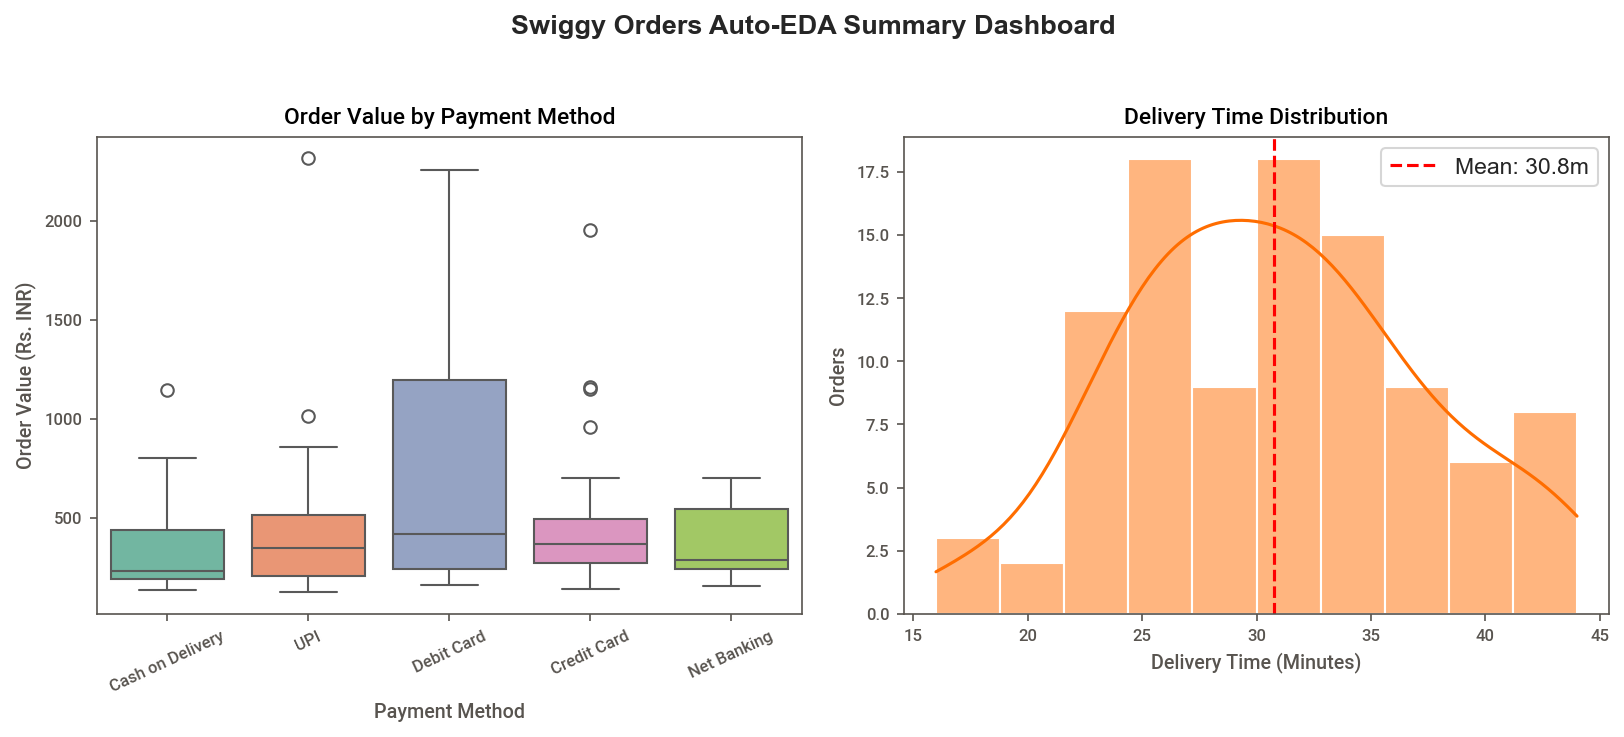

Summary Insights:
• Total Orders Processed:     100
• Mean Order Value:           ₹471.12
• Average Delivery Duration:  30.8 minutes
• Most Popular Payment Mode:  UPI (44.0%)


In [5]:
# Simulated AI Prompt:
# 'Prompt: Write clean Python code using Sweetviz to load swiggy_orders.csv, generate a comprehensive standalone HTML EDA report, and print summary order statistics.'

# Execute AI-generated code snippet
import sweetviz as sv
import pandas as pd
import matplotlib.pyplot as plt

df_swiggy = pd.read_csv("swiggy_orders.csv")
print("--- Swiggy Food Orders Dataset ---")
display(df_swiggy.head(6))

# Auto-EDA execution via Sweetviz
swiggy_report = sv.analyze(df_swiggy)
swiggy_html = "swiggy_orders_report.html"
swiggy_report.show_html(filepath=swiggy_html, open_browser=False)
print(f"\n[AI Snippet Output]: Report generated and saved to '{swiggy_html}'.")

# Visual proof summary dashboard
from IPython.display import Image, display as disp_img
disp_img(Image(filename="swiggy_eda_summary.png"))

print("Summary Insights:")
print(f"• Total Orders Processed:     {len(df_swiggy)}")
print(f"• Mean Order Value:           ₹{df_swiggy['order_value'].mean():.2f}")
print(f"• Average Delivery Duration:  {df_swiggy['delivery_time_mins'].mean():.1f} minutes")
print(f"• Most Popular Payment Mode:  {df_swiggy['payment_method'].mode()[0]} ({(df_swiggy['payment_method'] == 'UPI').mean()*100:.1f}%)")


---
## 🏢 Case Study Introduction: Superstore Sales Analysis (Kaggle Dataset)

To bridge individual EDA functions into an integrated enterprise workflow, we establish the **Superstore Sales Case Study**. This dataset captures multi-region transactional operations across diverse customer segments and product categories.

### Upcoming Analytical Modules:
1. **Sales & Gross Revenue Summary**: High-level tracking of top-performing lines and seasonal cycles.
2. **Profitability Analysis**: Detecting loss-making sub-categories despite high sales volume.
3. **Customer Segment Behavior**: Comparing buying frequency across *Consumer*, *Corporate*, and *Home Office* segments.
4. **Discount vs. Profit Erosion**: Evaluating margin cannibalization caused by aggressive discount thresholds (>20%).
5. **City & Regional Performance**: Geospatial mapping of profit contribution across geographic hubs.


In [6]:
# Ingest Superstore Sales Case Study Dataset
df_superstore = pd.read_csv("superstore_sales.csv")
print("--- Superstore Sales Dataset Sample ---")
display(df_superstore.head(6))

print("\n" + "="*70)
print("     SUPERSTORE SALES CASE STUDY: BASELINE DATASET METRICS")
print("="*70)
print(f"• Total Transaction Records:  {len(df_superstore):,}")
print(f"• Total Gross Revenue:       ${df_superstore['Sales'].sum():,.2f}")
print(f"• Total Operating Profit:    ${df_superstore['Profit'].sum():,.2f}")
print(f"• Overall Profit Margin:     {(df_superstore['Profit'].sum() / df_superstore['Sales'].sum())*100:.2f}%")
print(f"• Geographic Regions:        {list(df_superstore['Region'].unique())}")
print(f"• Product Categories:        {list(df_superstore['Category'].unique())}")
print(f"• Customer Segments:         {list(df_superstore['Customer_Segment'].unique())}")
print("="*70)

# Regional Gross Sales & Profit Breakdown
regional_summary = df_superstore.groupby("Region")[["Sales", "Profit"]].sum().reset_index()
regional_summary["Profit_Margin_%"] = (regional_summary["Profit"] / regional_summary["Sales"] * 100).round(2)
print("\nRegional Performance Breakdown:")
display(regional_summary.sort_values(by="Sales", ascending=False))


--- Superstore Sales Dataset Sample ---


,Order_ID,Order_Date,Ship_Mode,Customer_Segment,City,Region,Category,Sub_Category,Sales,Quantity,Discount,Profit
0,CA-2024-100001,2024-05-13,First Class,Consumer,Charlotte,South,Furniture,Bookcases,339.20,5,0.2,28.75
1,CA-2024-100002,2024-04-24,Standard Class,Corporate,Houston,Central,Office Supplies,Paper,394.82,7,0.1,105.77
2,CA-2024-100003,2024-06-14,Standard Class,Corporate,Dallas,Central,Office Supplies,Storage,374.52,2,0.0,65.40
3,CA-2024-100004,2024-11-07,Standard Class,Consumer,Philadelphia,East,Office Supplies,Storage,132.80,4,0.2,18.69
4,CA-2024-100005,2024-04-22,Second Class,Corporate,Philadelphia,East,Office Supplies,Storage,439.56,5,0.1,76.53
5,CA-2024-100006,2024-07-18,Standard Class,Corporate,Atlanta,South,Furniture,Bookcases,61.56,4,0.5,-2.63



     SUPERSTORE SALES CASE STUDY: BASELINE DATASET METRICS
• Total Transaction Records:  200
• Total Gross Revenue:       $65,364.01
• Total Operating Profit:    $12,862.46
• Overall Profit Margin:     19.68%
• Geographic Regions:        ['South', 'Central', 'East', 'West']
• Product Categories:        ['Furniture', 'Office Supplies', 'Technology']
• Customer Segments:         ['Consumer', 'Corporate', 'Home Office']

Regional Performance Breakdown:


,Region,Sales,Profit,Profit_Margin_%
0,Central,20594.01,4025.78,19.55
1,East,18802.07,4120.41,21.91
3,West,16326.95,3115.26,19.08
2,South,9640.98,1601.01,16.61


---
## 📌 Summary & Key Takeaways

1. **Auto-EDA Efficiency**:
   - `pandas-profiling` / `ydata-profiling` automates baseline health audits (missing values, cardinality, distributions) in seconds.
2. **Cohort Benchmarking (`Sweetviz`)**:
   - Side-by-side comparison (`sv.compare`) is the fastest approach for diagnosing regional (Mumbai vs. Delhi) or temporal shifts.
3. **Interactive Exploration (`D-Tale`)**:
   - Offers Excel-style interactivity within Jupyter Notebooks, streamlining targeted subset filtering without writing complex boolean queries.
4. **Translating Alerts into ETL Decisions**:
   - Profiling reports surface high-cardinality flags and null clusters that guide feature engineering and imputation strategies.
5. **Case Study Foundation**:
   - The Superstore Sales dataset is staged and ready for deep-dive exploratory analytics in subsequent modules.
